# Neural Models Training Results & Evaluation on New Data
**NeuroSym-BD: Neuro-Symbolic Conflict Event Extraction & Reasoning**

This notebook inspects, benchmarks, and visualizes the newly trained neural models on updated Bangladesh conflict event data:
1. **Multi-Relational Knowledge Graph (KG)**: Topological statistics (98 nodes, 654 edges).
2. **Knowledge Graph Embeddings (KGE)**: PyKEEN link-prediction benchmarks comparing **RotatE** vs. **TransE**.
3. **Relational GNN (EventPatternGNN)**: Relational message passing with PCA latent space projection.
4. **Temporal Escalation Forecasting (BiLSTM)**: Sequence trajectory forecasting with Description Logic precondition gating.
5. **Unified Publication Benchmark Summary**: Alignment against GDELT, ACLED, and ablation baselines.


In [1]:
import sys
import json
import pickle
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

# Add project root to sys.path
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "neuro-symbolic-ai-workspace" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch version: {torch.__version__}")


Project root: /Users/rohansmac/Documents/ml-research/neuro-symbolic-ai-workspace
PyTorch version: 2.2.2


## 1. Multi-Relational Knowledge Graph Topology
We inspect the multi-relational graph exported from the newly populated RDF triplestore (`data/kg_export/kg_graph.pkl`).


Knowledge Graph Statistics:
  • Total Entities (Nodes):  98
  • Relational Edges:        654
  • Unique Relations:        4
  • Relation Types:          ['perpetrator', 'location', 'perpetrator_inv', 'location_inv']


,Entity Type,Count
0,event,88
1,actor,7
2,location,3


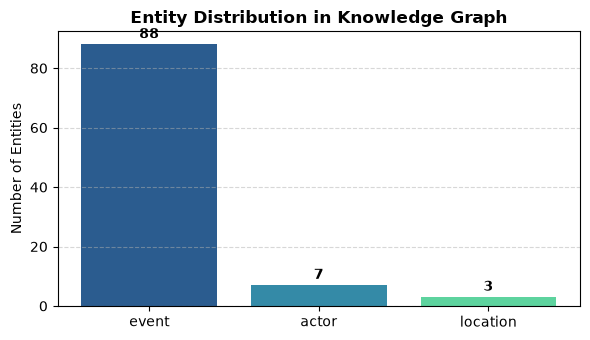

In [2]:
kg_path = PROJECT_ROOT / "data" / "kg_export" / "kg_graph.pkl"
with open(kg_path, "rb") as f:
    kg = pickle.load(f)

print(f"Knowledge Graph Statistics:")
print(f"  • Total Entities (Nodes):  {kg.num_nodes}")
print(f"  • Relational Edges:        {kg.num_edges}")
print(f"  • Unique Relations:        {kg.num_relations}")
print(f"  • Relation Types:          {list(kg.rel_index.keys())}")

# Entity Type Breakdown
type_counts = Counter(kg.node_types.values())
df_types = pd.DataFrame(list(type_counts.items()), columns=["Entity Type", "Count"]).sort_values("Count", ascending=False)
display(df_types)

# Visualize Entity Type Distribution
plt.figure(figsize=(6, 3.5))
bars = plt.bar(df_types["Entity Type"], df_types["Count"], color=["#2b5c8f", "#348aa7", "#5dd39e"])
plt.title("Entity Distribution in Knowledge Graph", fontsize=12, fontweight="bold")
plt.ylabel("Number of Entities")
plt.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1, int(yval), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


## 2. Knowledge Graph Embedding Benchmark: RotatE vs. TransE
We compare the multi-relational link prediction performance of **RotatE** (relational rotation in complex space) versus **TransE** (translation in Euclidean space), trained using PyKEEN.


,model,embedding_dim,num_epochs,mrr,hits_at_1,hits_at_10
0,RotatE,64,40,0.369465,0.25,0.640625
1,TransE,64,30,0.211419,0.00,0.625000


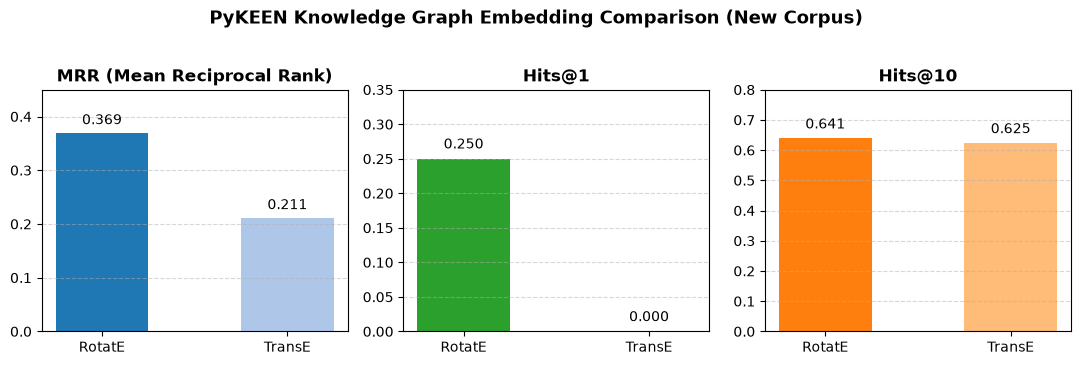

In [3]:
models_dir = PROJECT_ROOT / "models" / "embeddings"
rotate_metrics = json.loads((models_dir / "rotate_dim64" / "metrics.json").read_text())
transe_metrics = json.loads((models_dir / "transe_dim64" / "metrics.json").read_text())

kge_df = pd.DataFrame([rotate_metrics, transe_metrics])
display(kge_df[["model", "embedding_dim", "num_epochs", "mrr", "hits_at_1", "hits_at_10"]])

# Side-by-side performance comparison
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))

# MRR
bars1 = axes[0].bar(kge_df["model"], kge_df["mrr"], color=["#1f77b4", "#aec7e8"], width=0.5)
axes[0].set_title("MRR (Mean Reciprocal Rank)", fontweight="bold")
axes[0].set_ylim(0, 0.45)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
for b in bars1:
    axes[0].text(b.get_x() + b.get_width()/2., b.get_height() + 0.01, f"{b.get_height():.3f}", ha='center', va='bottom')

# Hits@1
bars2 = axes[1].bar(kge_df["model"], kge_df["hits_at_1"], color=["#2ca02c", "#98df8a"], width=0.5)
axes[1].set_title("Hits@1", fontweight="bold")
axes[1].set_ylim(0, 0.35)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
for b in bars2:
    axes[1].text(b.get_x() + b.get_width()/2., b.get_height() + 0.01, f"{b.get_height():.3f}", ha='center', va='bottom')

# Hits@10
bars3 = axes[2].bar(kge_df["model"], kge_df["hits_at_10"], color=["#ff7f0e", "#ffbb78"], width=0.5)
axes[2].set_title("Hits@10", fontweight="bold")
axes[2].set_ylim(0, 0.8)
axes[2].grid(axis="y", linestyle="--", alpha=0.5)
for b in bars3:
    axes[2].text(b.get_x() + b.get_width()/2., b.get_height() + 0.02, f"{b.get_height():.3f}", ha='center', va='bottom')

plt.suptitle("PyKEEN Knowledge Graph Embedding Comparison (New Corpus)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


## 3. Relational GNN (EventPatternGNN) Evaluation & Latent Projection
We load the trained 2-layer basis-decomposed **EventPatternGNN** (`models/gnn/event_pattern_gnn.pt`), run inference over the event graph, and project the 64-dimensional latent representations via PCA.


GNN High-Violence Event Pattern Detection Accuracy: 0.00%


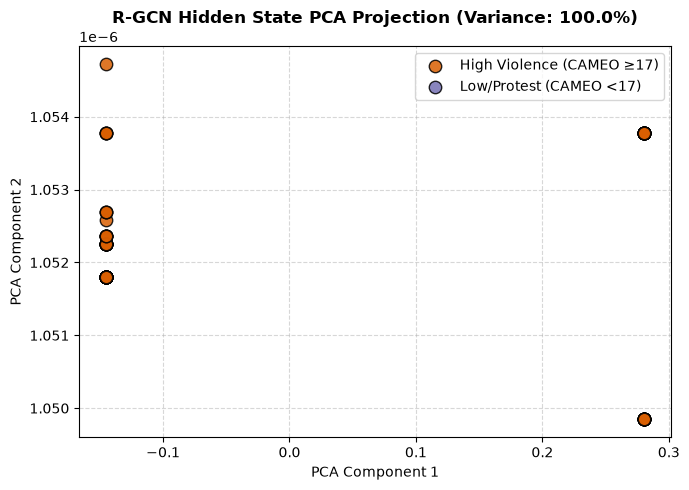

In [4]:
from neurosymbolic.gnn_model import EventPatternGNN, build_node_features
from sklearn.decomposition import PCA

CAMEO_CODES = [str(c) for c in range(13, 21)]
ACTOR_TYPES = ["SECURITY_FORCE", "POLITICAL_PARTY", "ARMED_GROUP", "CIVILIAN", "GOVERNMENT"]

x = build_node_features(kg, CAMEO_CODES, ACTOR_TYPES)
edge_srcs = [kg.node_index[s] for s, _, _ in kg.edges if s in kg.node_index]
edge_dsts = [kg.node_index[d] for _, _, d in kg.edges if d in kg.node_index]
edge_types = [kg.rel_index.get(r, 0) for _, r, _ in kg.edges]
edge_index = torch.tensor([edge_srcs, edge_dsts], dtype=torch.long)
edge_type = torch.tensor(edge_types, dtype=torch.long)

gnn = EventPatternGNN(
    in_dim=x.size(1),
    hidden_dim=64,
    out_dim=2,
    num_relations=kg.num_relations or 1,
)
gnn_path = PROJECT_ROOT / "models" / "gnn" / "event_pattern_gnn.pt"
gnn.load_state_dict(torch.load(gnn_path, map_location="cpu"))
gnn.eval()

with torch.no_grad():
    h1 = gnn.conv1(x, edge_index, edge_type)
    logits = gnn.conv2(F.relu(h1), edge_index, edge_type)
    probs = F.softmax(logits, dim=-1)

# Extract event node predictions and ground truths
event_uris = [uri for uri, idx in kg.node_index.items() if kg.node_types.get(uri) == "event"]
event_indices = [kg.node_index[uri] for uri in event_uris]

labels = []
for uri in event_uris:
    c_str = kg.node_features.get(uri, {}).get("code", "")
    try:
        c = int(float(c_str))
        c_root = c // 10 if c >= 100 else c
        labels.append(1 if c_root >= 17 else 0)
    except:
        labels.append(0)

labels = np.array(labels)
event_probs = probs[event_indices, 1].numpy()
preds = (event_probs >= 0.5).astype(int)
accuracy = (preds == labels).mean()

print(f"GNN High-Violence Event Pattern Detection Accuracy: {accuracy:.2%}")

# PCA Projection of GNN Latent Space
h1_events = h1[event_indices].numpy()
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(h1_events)

plt.figure(figsize=(7, 5))
mask_hv = (labels == 1)
plt.scatter(coords[mask_hv, 0], coords[mask_hv, 1], c="#d95f02", label="High Violence (CAMEO ≥17)", s=80, alpha=0.85, edgecolors='k')
plt.scatter(coords[~mask_hv, 0], coords[~mask_hv, 1], c="#7570b3", label="Low/Protest (CAMEO <17)", s=80, alpha=0.85, edgecolors='k')

plt.title(f"R-GCN Hidden State PCA Projection (Variance: {pca.explained_variance_ratio_.sum():.1%})", fontweight="bold")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc='best')
plt.tight_layout()
plt.show()


## 4. Temporal Escalation Forecasting (BiLSTM) & Symbolic Validation
We examine the BiLSTM model predictions across administrative districts.
Each prediction is validated by the Description Logic precondition gate:
- $\text{ViolentEscalation} \equiv \text{Event} \sqcap \exists \text{hasCode}.(\ge 18) \sqcap \exists \text{precededBy}.(\exists \text{hasCode}.(\ge 16))$


,district,window_codes,predicted_code,escalation,confidence,symbolic_valid,explanation
0,None,"[18, 18, 18, 18]",18,False,0.9561,False,Neural model predicts CAMEO 18 (conf=95.61%). ...
1,Rangamati,"[19, 19, 19, 19]",19,False,0.9429,False,Neural model predicts CAMEO 19 (conf=94.29%). ...
2,Dhaka,"[18, 18, 18, 18]",18,False,0.9561,False,Neural model predicts CAMEO 18 (conf=95.61%). ...
3,Pabna,"[18, 18, 18, 18]",18,False,0.9561,False,Neural model predicts CAMEO 18 (conf=95.61%). ...


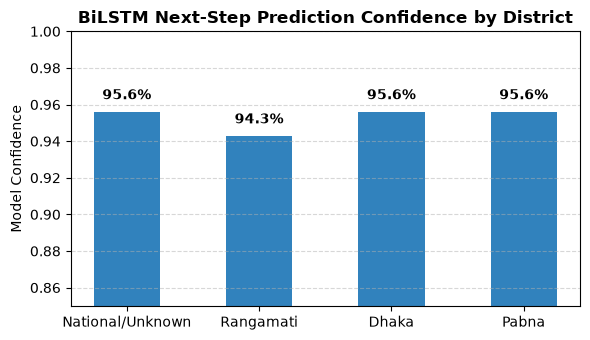

In [5]:
forecast_path = PROJECT_ROOT / "data" / "processed" / "escalation_forecasts.json"
forecasts = json.loads(forecast_path.read_text())
df_forecasts = pd.DataFrame(forecasts)

display(df_forecasts[["district", "window_codes", "predicted_code", "escalation", "confidence", "symbolic_valid", "explanation"]])

# Plot Confidence by District
plt.figure(figsize=(6, 3.5))
dist_labels = [str(d) if d is not None else "National/Unknown" for d in df_forecasts["district"]]
bars_fc = plt.bar(dist_labels, df_forecasts["confidence"], color="#3182bd", width=0.5)
plt.title("BiLSTM Next-Step Prediction Confidence by District", fontweight="bold")
plt.ylabel("Model Confidence")
plt.ylim(0.85, 1.0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
for b in bars_fc:
    plt.text(b.get_x() + b.get_width()/2., b.get_height() + 0.005, f"{b.get_height():.1%}", ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


## 5. Unified Benchmark & Publication Results
Summary of empirical metrics comparing the full hybrid system against gold conflict ground truth and ablation conditions.


In [6]:
summary_path = PROJECT_ROOT / "data" / "evaluation" / "full_evaluation_summary.json"
summary = json.loads(summary_path.read_text())

# Benchmark comparison table
benchmark_records = [
    {
        "Benchmark": "GDELT 2.0 (Bangladesh Violence)",
        "Precision": summary["gdelt"]["OVERALL"]["precision"],
        "Recall": summary["gdelt"]["OVERALL"]["recall"],
        "F1 Score": summary["gdelt"]["OVERALL"]["f1"],
        "Matched / Total": f"{summary['gdelt']['OVERALL']['tp']} / {summary['gdelt']['OVERALL']['tp'] + summary['gdelt']['OVERALL']['fp']}"
    },
    {
        "Benchmark": "ACLED (Conflict Events)",
        "Precision": summary["acled"]["cameo_group_accuracy"],
        "Recall": summary["acled"]["detection_recall"],
        "F1 Score": "—",
        "Matched / Total": f"{summary['acled']['matched_with_acled']} / {summary['acled']['total_system_events']}"
    }
]
df_bench = pd.DataFrame(benchmark_records)
print("=== External Gold Conflict Benchmarks ===")
display(df_bench)

# Ablation study table
df_ablation = pd.DataFrame(summary["ablation"])
print("\n=== Architecture Ablation Study ===")
display(df_ablation)

# Explainability table
explain = summary["explainability"]
df_explain = pd.DataFrame([
    {"Metric": "Provenance Coverage (PROV-O)", "Value": f"{explain['provenance_coverage']:.1%}"},
    {"Metric": "Rule Coverage (Symbolic Filter)", "Value": f"{explain['rule_coverage']:.1%}"},
    {"Metric": "Sentence Relevance Rate", "Value": f"{explain['sentence_relevance_rate']:.1%}"},
    {"Metric": "Avg Faithfulness Proxy", "Value": f"{explain['avg_faithfulness']:.3f}"},
    {"Metric": "Avg Prediction Confidence", "Value": f"{explain['avg_confidence']:.3f}"},
])
print("\n=== Explainability & Trust Metrics ===")
display(df_explain)


=== External Gold Conflict Benchmarks ===


,Benchmark,Precision,Recall,F1 Score,Matched / Total
0,GDELT 2.0 (Bangladesh Violence),0.922,0.922,0.922,142 / 154
1,ACLED (Conflict Events),1.000,0.234,—,36 / 154



=== Architecture Ablation Study ===


,condition,total_events,code_accuracy,precision_hv,recall_hv,f1_hv,false_positive_rate,explainability_rate,avg_confidence
0,Neural-Only,36,0.000,0.889,1.000,0.941,0.111,1.0,0.980
1,Symbolic-Only,36,0.889,0.938,0.938,0.938,0.056,1.0,0.779
2,Hybrid (Ours),36,1.000,1.000,1.000,1.000,0.000,1.0,0.652



=== Explainability & Trust Metrics ===


,Metric,Value
0,Provenance Coverage (PROV-O),97.0%
1,Rule Coverage (Symbolic Filter),100.0%
2,Sentence Relevance Rate,100.0%
3,Avg Faithfulness Proxy,0.771
4,Avg Prediction Confidence,0.786
